In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import itertools
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo
import cartopy.crs as ccrs
import pandas as pd
import gsw
from glob import glob
import matplotlib.patches as patches

import matplotlib.ticker as tkr
from matplotlib.lines import Line2D
from tqdm import tqdm
from datetime import datetime
import matplotlib.font_manager as fm


from xgcm import Grid
from xgcm.autogenerate import generate_grid_ds
import gsw

xr.set_options(keep_attrs=True)

from utils import make_map, subplots_structure, get_shelf_edge

In [3]:
zoomed_extent= [-48, -34, -30, -16] # [-45, -39, -27, -22]

datadir = '../data/glorys'

flist = sorted(glob(f"{datadir}/smax_*.nc"))
glorys = xr.open_mfdataset(flist)

# loading glider track
glider = xr.open_dataset(f"../data/glider/sg576_Azul_19")

# Comparing GLORYS with Slocum glider

In [14]:
# convert both glider and glorys to SA and CT
glider['pressure'] = gsw.p_from_z((-1)*glider['depth'], glider['latitude'])
glider['salinity'] = gsw.SA_from_SP(glider['salinity'], glider['pressure'], glider['longitude'], glider['latitude'])
glider['temperature'] = gsw.CT_from_t(glider['salinity'], glider['temperature'], glider['pressure'])

glorys['pressure'] = gsw.p_from_z((-1)*glorys['depth'], glorys['latitude'])
glorys['so'] = gsw.SA_from_SP(glorys['so'], glorys['pressure'], glorys['longitude'], glorys['latitude'])
glorys['thetao'] = gsw.CT_from_t(glorys['so'], glorys['thetao'], glorys['pressure'])

### Investigating

Understanding how Slocum Glider profiles change within a single GLORYS grid cell for a given day, to plan the better approach for computing the RMSE between glorys and glider.

In [15]:
import numpy as np, pandas as pd, xarray as xr, matplotlib.pyplot as plt

prof_lon = glider.longitude.mean("depth") if "depth" in glider.longitude.dims else glider.longitude
prof_lat = glider.latitude.mean("depth")  if "depth" in glider.latitude.dims  else glider.latitude

glorys = glorys.sel(
    latitude=slice(float(prof_lat.min()) - 0.1, float(prof_lat.max()) + 0.1),
    longitude=slice(float(prof_lon.min()) - 0.1, float(prof_lon.max()) + 0.1),
).load()

In [16]:
prof = pd.DataFrame({
    "time": glider.time.values,
    "lon":  prof_lon.values,
    "lat":  prof_lat.values,
}).dropna(subset=["lon", "lat"]).reset_index(drop=True)

prof["cell_lon"] = glorys.longitude.sel(
    longitude=xr.DataArray(prof.lon.values, dims="i"), method="nearest").values
prof["cell_lat"] = glorys.latitude.sel(
    latitude=xr.DataArray(prof.lat.values, dims="i"), method="nearest").values
prof["day"] = prof.time.values.astype("datetime64[D]")

In [17]:
counts = (prof.groupby(["cell_lat", "cell_lon"])
              .size().reset_index(name="n_profiles")
              .sort_values("n_profiles", ascending=False))
print(counts)

members = prof.groupby(["cell_lat", "cell_lon"])["time"].apply(list)   # times in each cell

      cell_lat   cell_lon  n_profiles
40  -25.083334 -41.250000          28
52  -25.000000 -41.250000          19
131 -24.583334 -42.000000          15
143 -24.583334 -40.250000          15
126 -24.666666 -40.166668          14
..         ...        ...         ...
227 -24.000000 -41.250000           1
14  -25.250000 -41.583332           1
118 -24.666666 -41.500000           1
115 -24.666666 -42.000000           1
0   -25.500000 -41.333332           1

[268 rows x 3 columns]


1 glider profiles in cell (-24.417, -41.750) on 2022-03-27


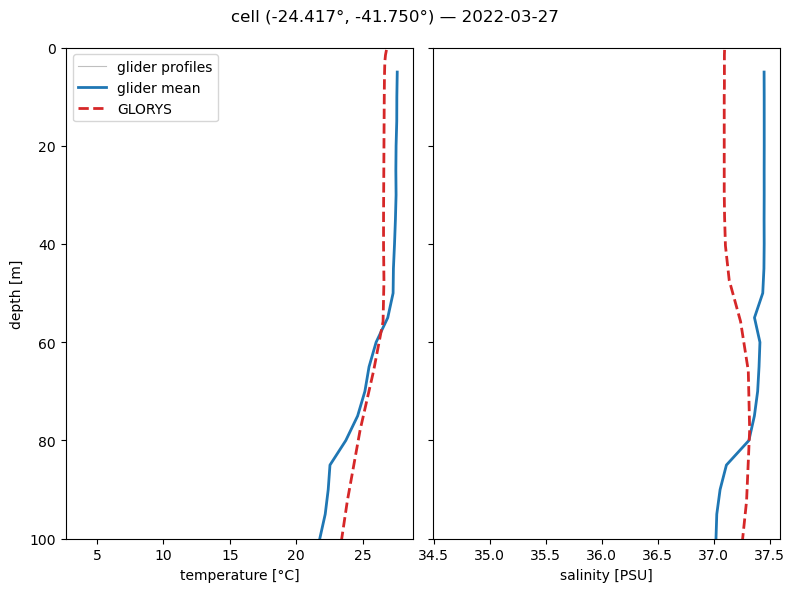

In [20]:
# Filter to one day, then take the cell with the most profiles that day:

# choose the day
sel_day = np.datetime64("2022-03-27")
sub = prof[prof.day == sel_day]

# choose the grid cell based on the max number of profiles
cell_lat_sel, cell_lon_sel = sub.groupby(["cell_lat", "cell_lon"]).size().idxmin()
sel = sub[(sub.cell_lat == cell_lat_sel) & (sub.cell_lon == cell_lon_sel)]
sel_times = sel.time.values
print(f"{len(sel_times)} glider profiles in cell "
      f"({cell_lat_sel:.3f}, {cell_lon_sel:.3f}) on {sel_day}")

g = glider.sel(time=sel_times)              # (selected time, depth)
g_T_mean = g.temperature.mean("time")
g_S_mean = g.salinity.mean("time")

gl = (glorys.sel(time=sel_day, method="nearest")
            .sel(latitude=cell_lat_sel, longitude=cell_lon_sel, method="nearest"))

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(8, 6))
for k, t in enumerate(sel_times):
    gt = g.sel(time=t)
    ax[0].plot(gt.temperature, g.depth, color="0.75", lw=0.8,
               label="glider profiles" if k == 0 else None)
    ax[1].plot(gt.salinity, g.depth, color="0.75", lw=0.8)

ax[0].plot(g_T_mean, g.depth, color="C0", lw=2, label="glider mean")
ax[1].plot(g_S_mean, g.depth, color="C0", lw=2)
ax[0].plot(gl.thetao, gl.depth, color="C3", lw=2, ls="--", label="GLORYS")
ax[1].plot(gl.so, gl.depth, color="C3", lw=2, ls="--")

ax[0].set_ylim(0, 100)
ax[0].invert_yaxis()
ax[0].set_ylabel("depth [m]")
ax[0].set_xlabel("temperature [°C]")
ax[1].set_xlabel("salinity [PSU]")
ax[0].legend()
fig.suptitle(f"cell ({cell_lat_sel:.3f}°, {cell_lon_sel:.3f}°) — {sel_day}")
fig.tight_layout()

4 glider profiles in cell (-24.667, -42.417) on 2022-03-15


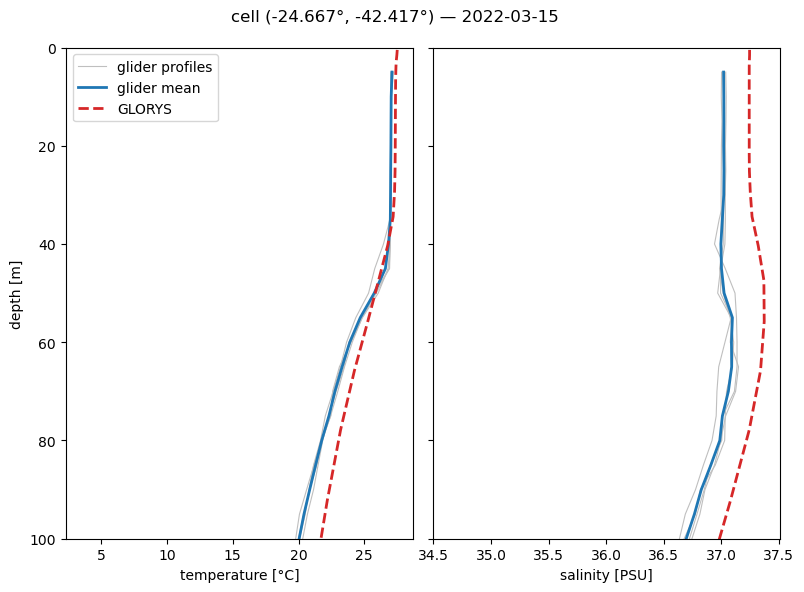

In [19]:
# Filter to one day, then take the cell with the most profiles that day:

# choose the day
sel_day = np.datetime64("2022-03-15")
sub = prof[prof.day == sel_day]

# choose the grid cell based on the max number of profiles
cell_lat_sel, cell_lon_sel = sub.groupby(["cell_lat", "cell_lon"]).size().idxmax()
sel = sub[(sub.cell_lat == cell_lat_sel) & (sub.cell_lon == cell_lon_sel)]
sel_times = sel.time.values
print(f"{len(sel_times)} glider profiles in cell "
      f"({cell_lat_sel:.3f}, {cell_lon_sel:.3f}) on {sel_day}")

g = glider.sel(time=sel_times)              # (selected time, depth)
g_T_mean = g.temperature.mean("time")
g_S_mean = g.salinity.mean("time")

gl = (glorys.sel(time=sel_day, method="nearest")
            .sel(latitude=cell_lat_sel, longitude=cell_lon_sel, method="nearest"))

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(8, 6))
for k, t in enumerate(sel_times):
    gt = g.sel(time=t)
    ax[0].plot(gt.temperature, g.depth, color="0.75", lw=0.8,
               label="glider profiles" if k == 0 else None)
    ax[1].plot(gt.salinity, g.depth, color="0.75", lw=0.8)

ax[0].plot(g_T_mean, g.depth, color="C0", lw=2, label="glider mean")
ax[1].plot(g_S_mean, g.depth, color="C0", lw=2)
ax[0].plot(gl.thetao, gl.depth, color="C3", lw=2, ls="--", label="GLORYS")
ax[1].plot(gl.so, gl.depth, color="C3", lw=2, ls="--")

ax[0].set_ylim(0, 100)
ax[0].invert_yaxis()
ax[0].set_ylabel("depth [m]")
ax[0].set_xlabel("temperature [°C]")
ax[1].set_xlabel("salinity [PSU]")
ax[0].legend()
fig.suptitle(f"cell ({cell_lat_sel:.3f}°, {cell_lon_sel:.3f}°) — {sel_day}")
fig.tight_layout()

4 glider profiles in cell (-24.583, -42.000) on 2022-03-01


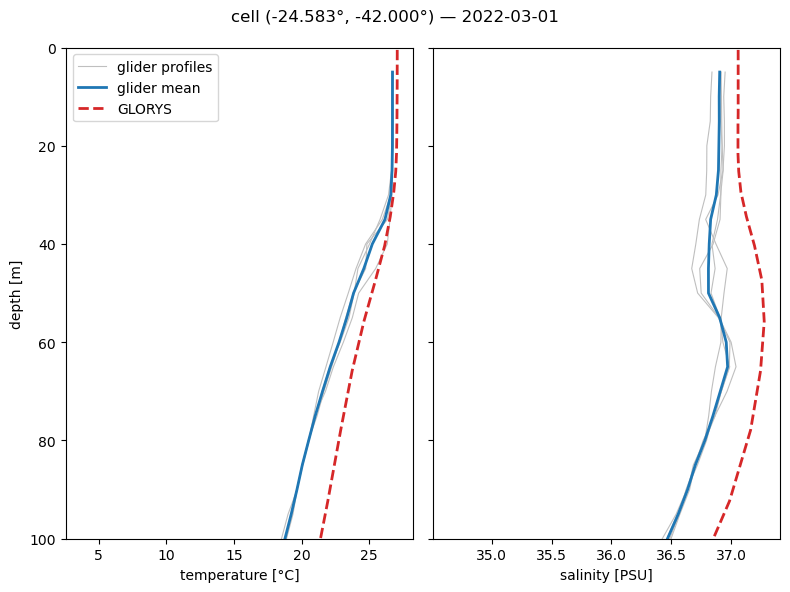

In [32]:
# Filter to one day, then take the cell with the most profiles that day:

# choose the day
sel_day = np.datetime64("2022-03-01")
sub = prof[prof.day == sel_day]

# choose the grid cell based on the max number of profiles
cell_lat_sel, cell_lon_sel = sub.groupby(["cell_lat", "cell_lon"]).size().idxmax()
sel = sub[(sub.cell_lat == cell_lat_sel) & (sub.cell_lon == cell_lon_sel)]
sel_times = sel.time.values
print(f"{len(sel_times)} glider profiles in cell "
      f"({cell_lat_sel:.3f}, {cell_lon_sel:.3f}) on {sel_day}")

g = glider.sel(time=sel_times)              # (selected time, depth)
g_T_mean = g.temperature.mean("time")
g_S_mean = g.salinity.mean("time")

gl = (glorys.sel(time=sel_day, method="nearest")
            .sel(latitude=cell_lat_sel, longitude=cell_lon_sel, method="nearest"))

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(8, 6))
for k, t in enumerate(sel_times):
    gt = g.sel(time=t)
    ax[0].plot(gt.temperature, g.depth, color="0.75", lw=0.8,
               label="glider profiles" if k == 0 else None)
    ax[1].plot(gt.salinity, g.depth, color="0.75", lw=0.8)

ax[0].plot(g_T_mean, g.depth, color="C0", lw=2, label="glider mean")
ax[1].plot(g_S_mean, g.depth, color="C0", lw=2)
ax[0].plot(gl.thetao, gl.depth, color="C3", lw=2, ls="--", label="GLORYS")
ax[1].plot(gl.so, gl.depth, color="C3", lw=2, ls="--")

ax[0].set_ylim(0, 100)
ax[0].invert_yaxis()
ax[0].set_ylabel("depth [m]")
ax[0].set_xlabel("temperature [°C]")
ax[1].set_xlabel("salinity [PSU]")
ax[0].legend()
fig.suptitle(f"cell ({cell_lat_sel:.3f}°, {cell_lon_sel:.3f}°) — {sel_day}")
fig.tight_layout()

In [21]:
diffs_T, diffs_S = [], []

for (day, clat, clon), grp in prof.groupby(["day", "cell_lat", "cell_lon"]):
    g = glider.sel(time=grp.time.values)            # profiles in this cell on this day
    gmean_T = g.temperature.mean("time")            # cell-averaged glider profile (glider depths)
    gmean_S = g.salinity.mean("time")

    gl = (glorys.sel(time=day, method="nearest")
                .sel(latitude=clat, longitude=clon, method="nearest"))
    gl_T = gl.thetao.interp(depth=glider.depth)     # GLORYS onto the glider depth axis
    gl_S = gl.so.interp(depth=glider.depth)

    diffs_T.append((gmean_T - gl_T).values)         # convention: glider − GLORYS (obs − model)
    diffs_S.append((gmean_S - gl_S).values)

diffs_T = np.vstack(diffs_T)                          # (n_colocations, n_depth)
diffs_S = np.vstack(diffs_S)

mean_diff_T = np.nanmean(diffs_T, axis=0)
mean_diff_S = np.nanmean(diffs_S, axis=0)
rmse_T = np.sqrt(np.nanmean(diffs_T ** 2, axis=0))
rmse_S = np.sqrt(np.nanmean(diffs_S ** 2, axis=0))
n_per_depth = np.isfinite(diffs_T).sum(axis=0)        # co-locations contributing at each depth

In [28]:
n_per_depth

array([573, 573, 573, 573, 573, 573, 573, 573, 573, 573, 573, 573, 573,
       573, 573, 573, 573, 573, 573, 573,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0])

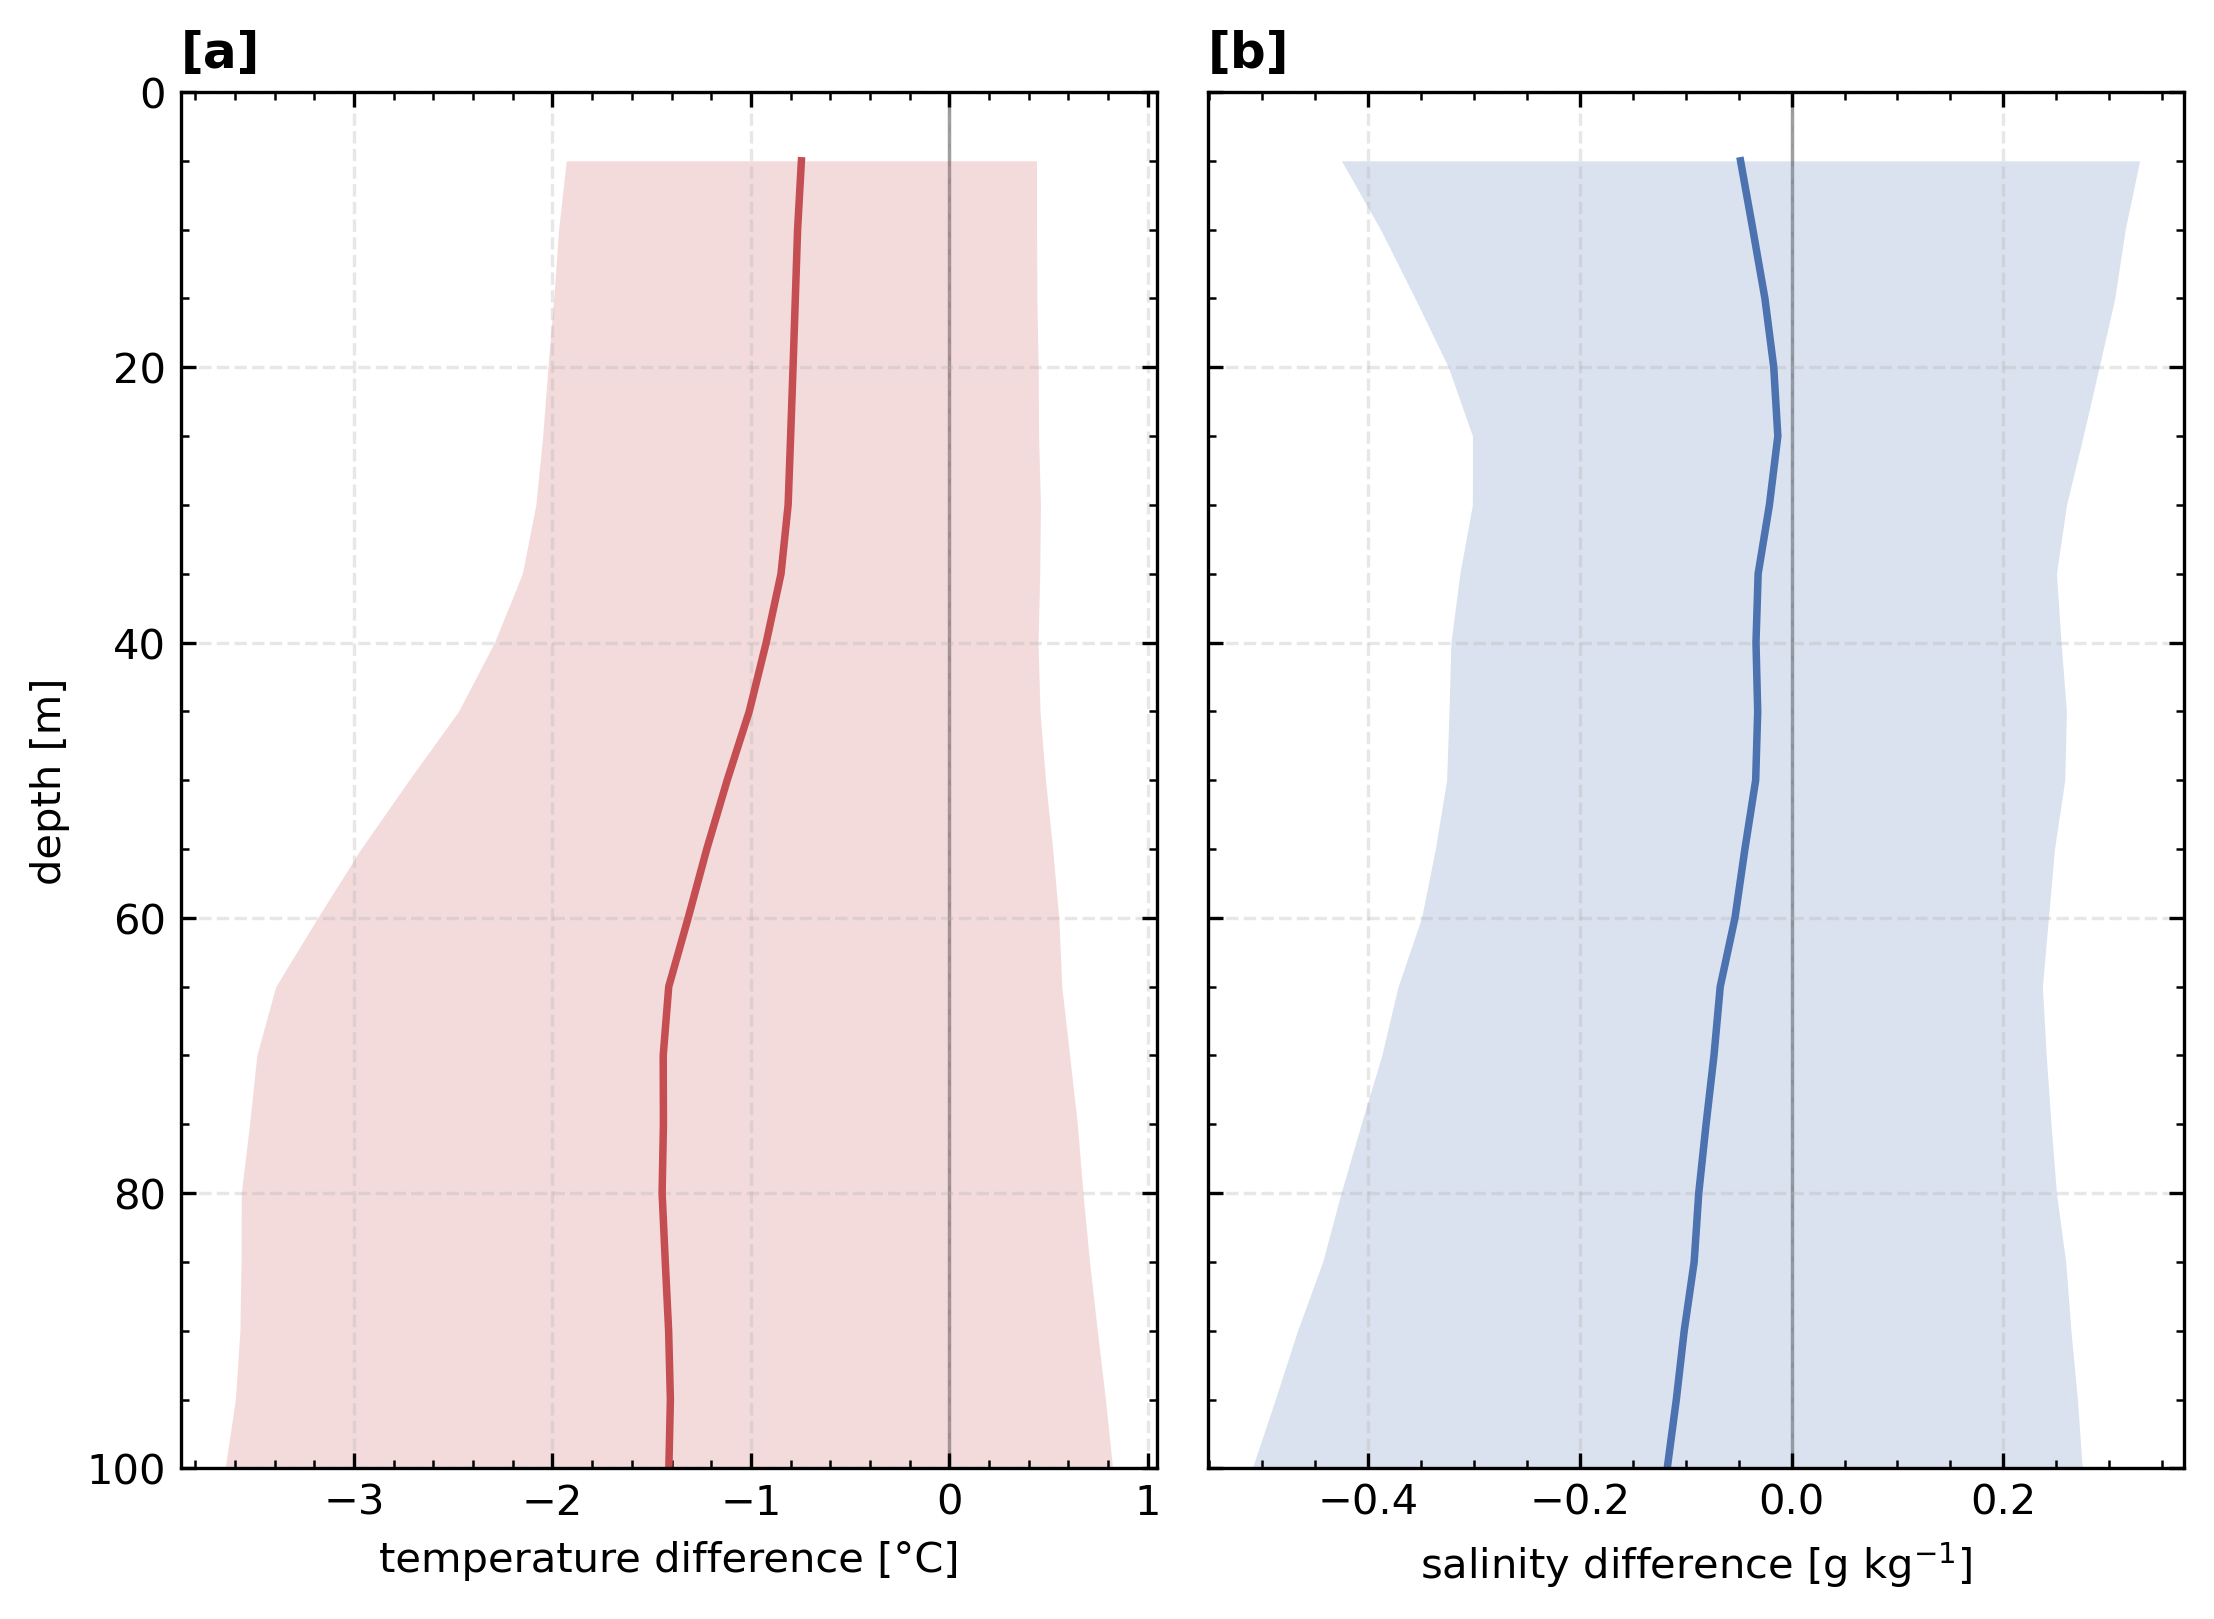

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# arrays from Phase B, sorted by depth
depth = glider.depth.values
order = np.argsort(depth)
depth = depth[order]
mean_diff_T, rmse_T = mean_diff_T[order], rmse_T[order]
mean_diff_S, rmse_S = mean_diff_S[order], rmse_S[order]

# depth-averaged summary, and the surface / 100-m levels
mT, rT = np.nanmean(mean_diff_T), np.nanmean(rmse_T)
mS, rS = np.nanmean(mean_diff_S), np.nanmean(rmse_S)
i_surf = int(np.nanargmin(np.abs(depth - 0)))
i_100  = int(np.nanargmin(np.abs(depth - 100)))

col_T, col_S = '#c44e52', '#4c72b0'

fig, axes = plt.subplots(ncols=2, sharey=True, figsize=(7.48, 5.5), dpi=300)

# --- temperature (a) ---
axes[0].fill_betweenx(depth, mean_diff_T - rmse_T, mean_diff_T + rmse_T,
                      color=col_T, alpha=0.2, lw=0)
axes[0].plot(mean_diff_T, depth, color=col_T, lw=1.8)

# --- salinity (b) ---
axes[1].fill_betweenx(depth, mean_diff_S - rmse_S, mean_diff_S + rmse_S,
                      color=col_S, alpha=0.2, lw=0)
axes[1].plot(mean_diff_S, depth, color=col_S, lw=1.8)

axes[0].set_ylim(0, 100)
axes[0].invert_yaxis()

txt_T = (f'RMSE({depth[i_surf]:.0f} m) = {rmse_T[i_surf]:.2f} °C\n'
         f'RMSE({depth[i_100]:.0f} m) = {rmse_T[i_100]:.2f} °C')
txt_S = (f'RMSE({depth[i_surf]:.0f} m) = {rmse_S[i_surf]:.2f} g kg'+r'$^{-1}$' + '\n'
         f'RMSE({depth[i_100]:.0f} m) = {rmse_S[i_100]:.2f} g kg'+r'$^{-1}$')

axes[0].text(0.018, 0.98, txt_T, transform=axes[0].transAxes, ha='left', va='top',
             fontsize=8, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.9))
axes[1].text(0.018, 0.98, txt_S, transform=axes[1].transAxes, ha='left', va='top',
             fontsize=8, bbox=dict(boxstyle='round', fc='white', ec='0.7', alpha=0.9))

axes[0].set_title('[a]', loc='left') #, fontweight='bold')
axes[1].set_title('[b]', loc='left') #, fontweight='bold')

for ax in axes:
    # ax.axvline(0, color='0.6', lw=0.8, zorder=0)
    ax.grid(True, ls='--', alpha=.3)
    ax.minorticks_on()
    ax.tick_params(direction='in', which='both', top=True, right=True)

axes[0].set_ylabel('Depth [m]')
axes[0].set_xlabel('temperature difference [°C]')
axes[1].set_xlabel(r'absolute salinity difference [g kg$^{-1}$]')

fig.tight_layout()
plt.savefig('../figures/manuscript/00_manuscript_supp_glorys_RMSE.png', bbox_inches="tight", dpi=300)

# Comparing vertical profiles between train profiles and glorys

In [58]:
from load_profiles import load_vertical_profiles

In [59]:
def clean_axis(ax, list_axes=['bottom', 'right', 'left']):
    for edge_i in list_axes:
        ax.spines[edge_i].set_edgecolor("white")
    return ax

def clean_ticks(ax, left=False, bottom=False):
    if left:
        ax.yaxis.set_tick_params(labelleft=False)
        ax.set_yticks([])
    if bottom:
        ax.xaxis.set_tick_params(labelbottom=False)
        ax.set_xticks([])

In [60]:
bathy = xr.open_dataset('../data/gebco_2019.nc')
# rename variables for a padronization
bathy = bathy.rename({'elevation': 'depth'})
bathy = bathy.where(bathy['depth'] < 0, drop=True)

# regional selection (for both dataset loaded)
lon_lower, lon_upper = zoomed_extent[0], zoomed_extent[1] #-50, -40
lat_lower, lat_upper = zoomed_extent[2], zoomed_extent[3] #-29, -23

# bathymetry
bathy = bathy.sel(lon=slice(lon_lower, lon_upper),
                lat=slice(lat_lower, lat_upper))

In [61]:
datadir_ctd = '/home/danilo/phd/thesis/chapter_colab/scripts/section-ctd_dalton/data/umassd2/treated'
datadir_argo = '/home/danilo/phd/thesis/smax_pathways/data/argo'
datadir_glider = '/home/danilo/phd/thesis/smax_pathways/data/glider'

profile_fig_config = {
    'figsize': [5,10],
    'x-label': 'absolute salinity [g/kg]',
    'y-label': 'depth [m]',
    'x-range': [34.5, 37.5],
    'y-range': [-200,0],
}

order_plot = ['cast1', 'cast3.2', 'cast2', 'cast6', 'cast7']
letters = 'a b c d e f'.split(' ')
letters

['a', 'b', 'c', 'd', 'e', 'f']

In [62]:
dict_casts = load_vertical_profiles()

Processing cast1...
Processing cast2...
Processing cast3.2...
Processing cast6...
Processing cast7...


In [63]:
def get_glorys_profile(cast, glorys, convert=False):
    
    prof_model = glorys.sel(time=cast['prof'].attrs['time'],
          longitude=cast['prof'].attrs['lon'],
          latitude=cast['prof'].attrs['lat'],
          method='nearest'
         )

    ymodel = prof_model['depth'].values * (-1)

    if convert:
        p  = gsw.p_from_z(ymodel, prof_model.latitude.item())                 # pressure from depth, sign-aware
        salt = gsw.SA_from_SP(prof_model['so'].values, p, prof_model.longitude.item(), prof_model.latitude.item())
        temp = gsw.pt0_from_t(salt, prof_model.thetao, p)             # potential temperature, ref 0 dbar
    else:
        salt = prof_model['so'].values
        temp =prof_model['thetao'].values

    return salt, temp, ymodel

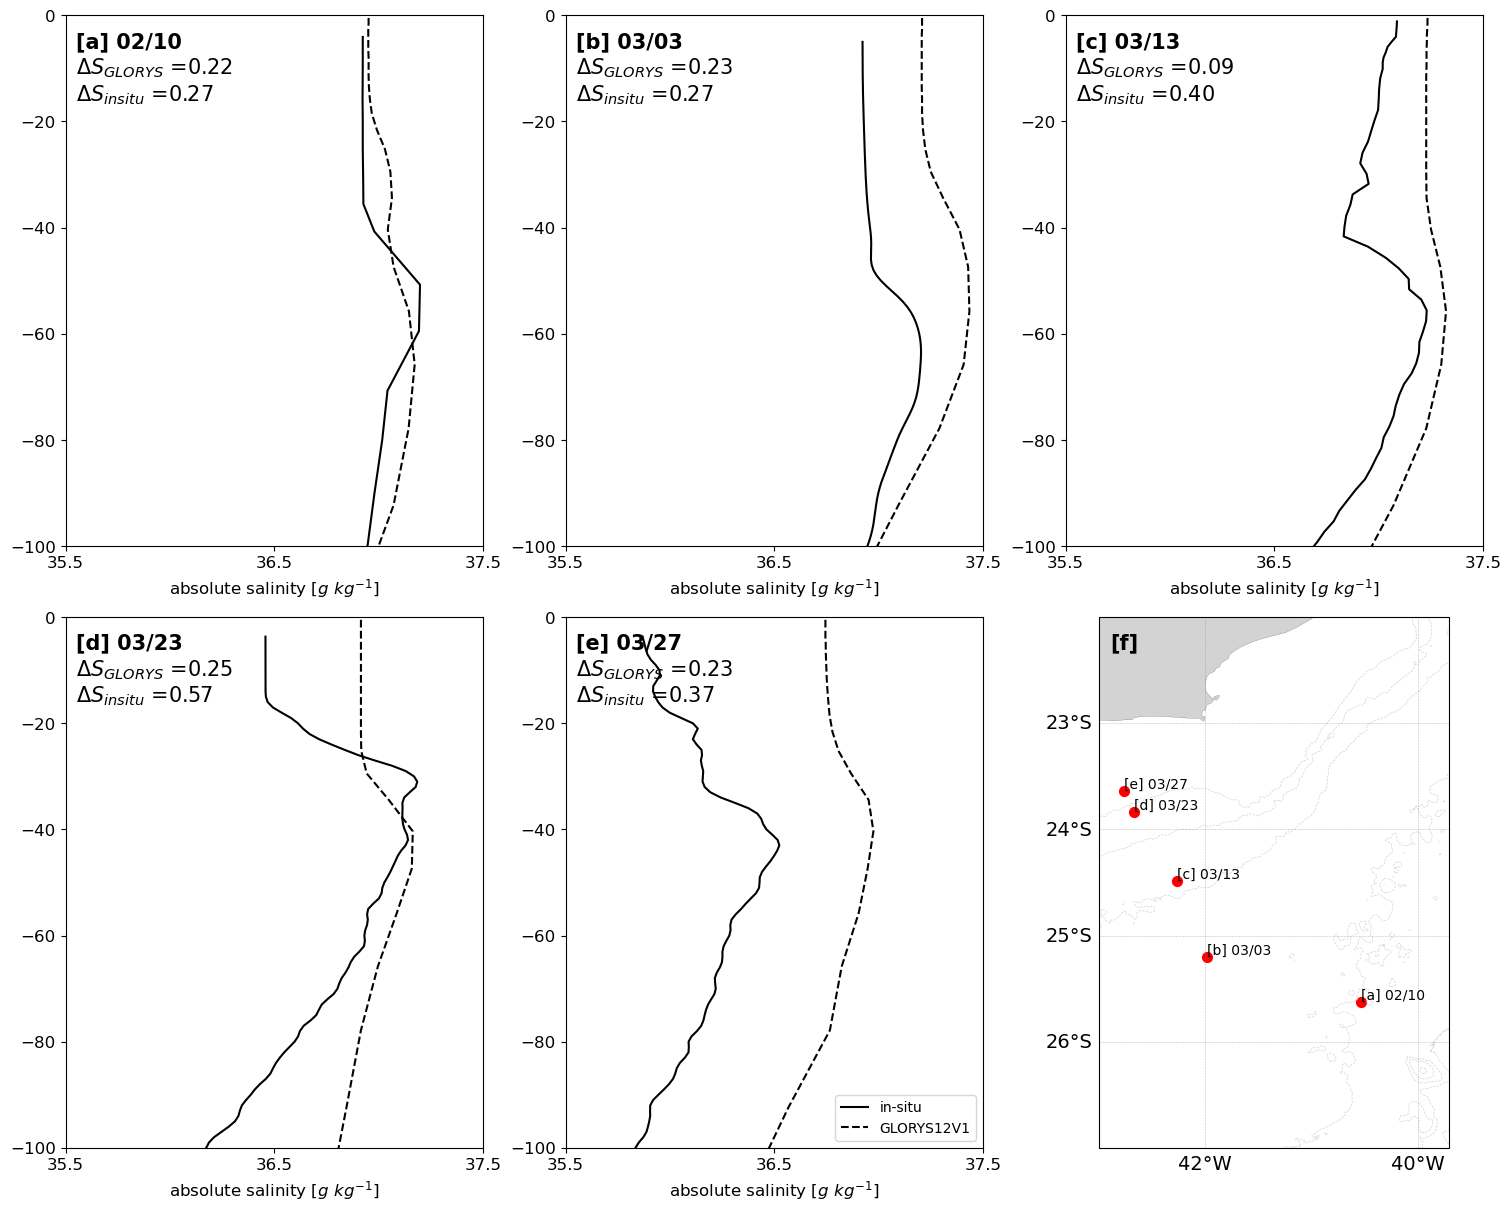

In [149]:
import matplotlib.pyplot as plt

from matplotlib.gridspec import GridSpec

ref_depth = [20, 20, 42, 20, 25]

fig = plt.figure(layout="constrained", figsize=(15,12))

gs = GridSpec(2, 6, figure=fig)

ax1 = fig.add_subplot(gs[0,:2])
ax2 = fig.add_subplot(gs[0,2:4])
ax3 = fig.add_subplot(gs[0,4:])

ax4 = fig.add_subplot(gs[1,:2])
ax5 = fig.add_subplot(gs[1,2:4])

axes = [ax1, ax2, ax3, ax4, ax5]

_ = [ax.set_xlim([35.5,37.5]) for ax in axes]
_ = [ax.set_ylim([-100,0]) for ax in axes]

# plotting
for i,c in enumerate(order_plot):
    ax = axes[i]
    prof = dict_casts[c]['prof'] #keys[c]
    sa_model, _, ymodel = get_glorys_profile(dict_casts[c], glorys)

    ax.set_xlabel('absolute salinity '+r'[$g\ kg^{-1}$]', fontsize=12, color='k')

    indmax = np.argmax(prof['salt'].values)
    
    ax.plot(prof['salt'], prof['dept'], c='k', label='in-situ')
    ax.plot(sa_model, ymodel, c='k', ls='--', label='GLORYS12V1')

    # --- salinity-maximum anomaly (GLORYS), upper 100 m ---
    i_smax  = np.nanargmax(sa_model)
    s_max   = sa_model[i_smax]
    idx20   = np.abs(ymodel * (-1) - 10).argmin()          # nearest level to 20 m
    anomaly = s_max - sa_model[idx20]

    # --- salinity-maximum anomaly (INSITU), upper 100 m ---
    sa_ref = prof.salt.values[np.abs(prof.dept.values * (-1) - ref_depth[i]).argmin()]
    s_max = prof['salt'].max().item()
    anomaly_insitu = s_max - sa_ref
    
    # ax.text(35.4, -6, f'[{letters[i]}] {prof.attrs["time"].strftime("%m/%d")}',
    #         fontweight='bold', fontsize=15)
    ax.text(35.55, -6, f'[{letters[i]}] {prof.attrs["time"].strftime("%m/%d")}', 
            fontweight='bold', fontsize=15)
    ax.text(35.55, -11, r'$\Delta{S}_{GLORYS}$ =' + f'{anomaly:.2f}', fontsize=15)
    ax.text(35.55, -16, r'$\Delta{S}_{insitu}$ =' + f'{anomaly_insitu:.2f}', fontsize=15)

_ = [ax.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True) for ax in axes]
_ = [ax.set_xticks([35.5, 36.5, 37.5]) for ax in axes]

plt.legend(loc='lower right')

plt.subplots_adjust(wspace=.4)

ax = fig.add_subplot(gs[1,4:], projection = ccrs.PlateCarree())
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent([-43, -39.7, -27, -22])
# ax.set_title('[f]', loc='left')
ax.text(-42.9, -22.3, '[f]', fontweight='bold', fontsize=15)

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -2000, -3000, -4000], 
                         colors=('lightgray'), linewidths=(0.5), linestyles=('--'))

varbs = [['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['lon', 'lat'],
         [],
        ]

# plotting
cont = 0
letters = 'a b c d e'.split(' ')
for i,cast in enumerate(order_plot):
# for cast,values in dict_casts.items():
    values = dict_casts[cast]
    prof = values['prof'] #keys[c]

    str_time = f'[{letters[cont]}] {values["time"].strftime("%m/%d")}'
    xlon = prof.attrs['lon']
    ylat = prof.attrs['lat']
    cont += 1
    c='red'
    
    ax.scatter(xlon, ylat, c=c, s=50)
    ax.text(xlon, ylat, str_time, ha='left', va='bottom')

for ax in axes:
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    
fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_supp_train_profiles_GLORYS_comparison_salt.png', bbox_inches="tight", dpi=300)

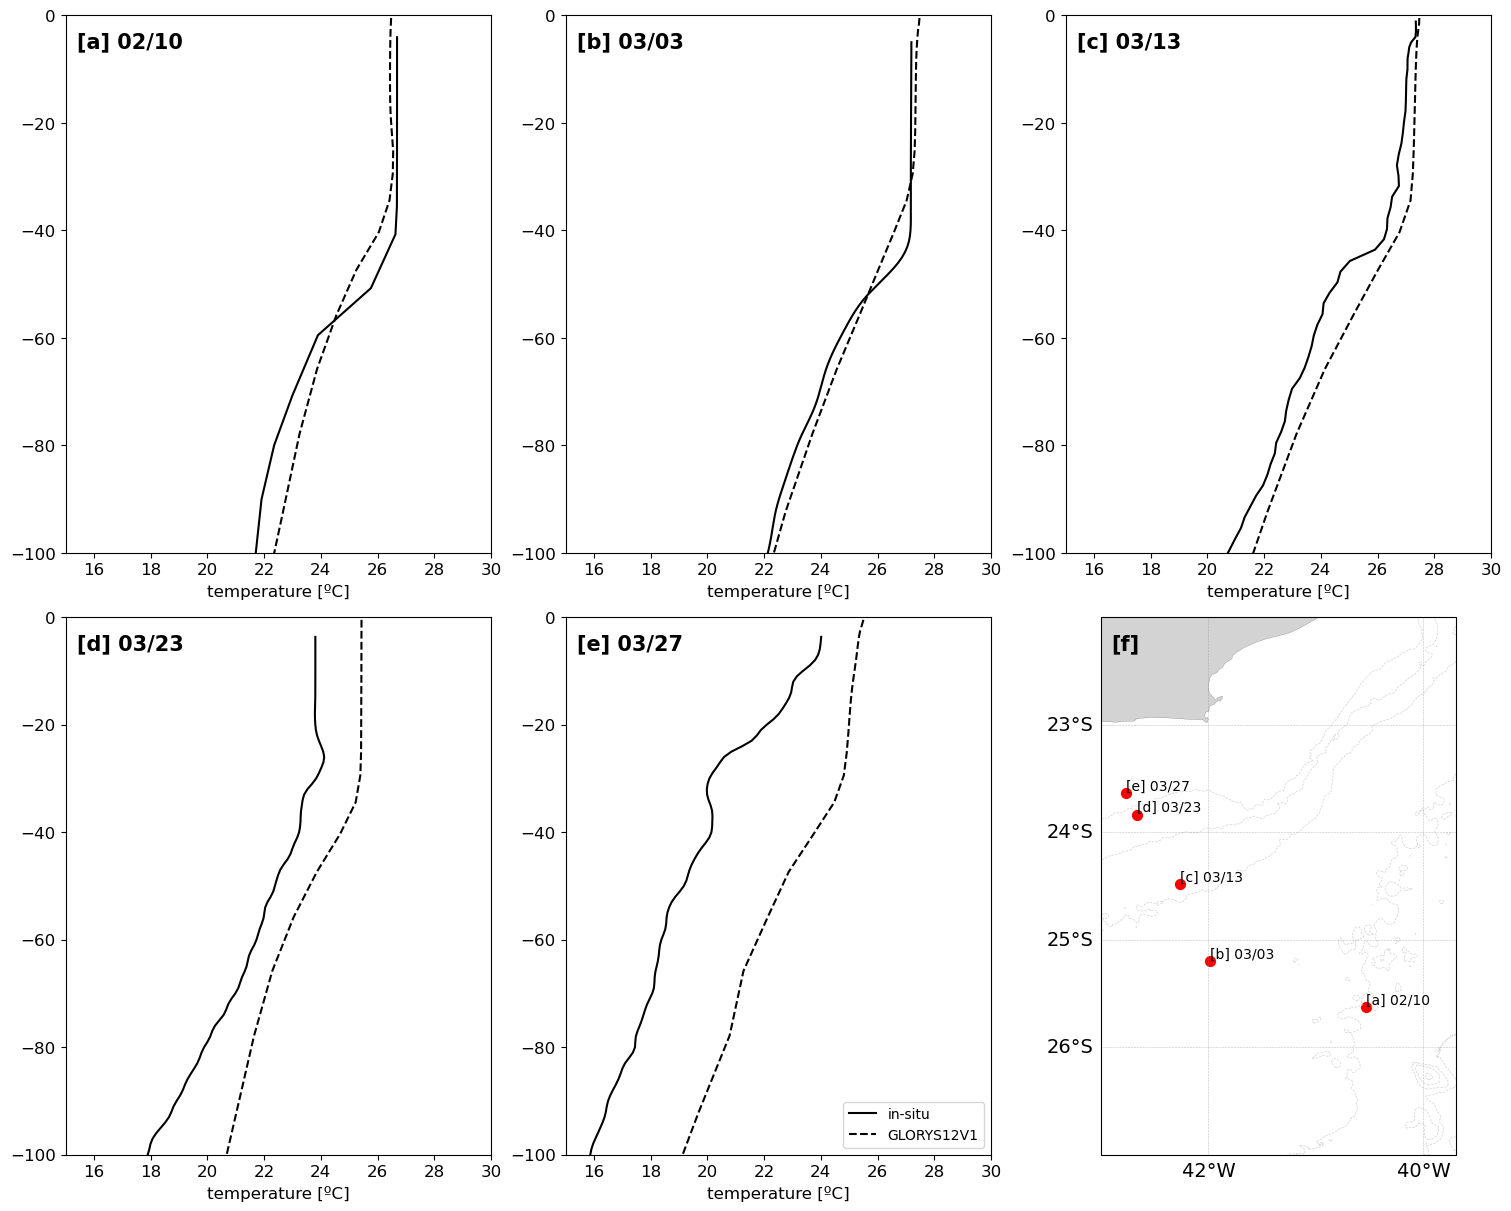

In [147]:
import matplotlib.pyplot as plt

from matplotlib.gridspec import GridSpec

fig = plt.figure(layout="constrained", figsize=(15,12))

gs = GridSpec(2, 6, figure=fig)

ax1 = fig.add_subplot(gs[0,:2])
ax2 = fig.add_subplot(gs[0,2:4])
ax3 = fig.add_subplot(gs[0,4:])

ax4 = fig.add_subplot(gs[1,:2])
ax5 = fig.add_subplot(gs[1,2:4])

axes = [ax1, ax2, ax3, ax4, ax5]

_ = [ax.set_xlim([15,30]) for ax in axes]
_ = [ax.set_ylim([-100,0]) for ax in axes]

# plotting
for i,c in enumerate(order_plot):
    ax = axes[i]
    prof = dict_casts[c]['prof'] #keys[c]
    sa_model, t_model, ymodel = get_glorys_profile(dict_casts[c], glorys)

    ax.set_xlabel('temperature [ºC]', fontsize=12, color='k')

    x = prof['temp']
    y = prof['dept']
    
    ax.plot(x, y, c='k', label='in-situ')
    ax.plot(t_model, ymodel, c='k', ls='--', label='GLORYS12V1')

    ax.text(15.4, -6, f'[{letters[i]}] {prof.attrs["time"].strftime("%m/%d")}', fontweight='bold', fontsize=15)

_ = [ax.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True) for ax in axes]
# _ = [ax.set_xticks([35.5, 36.5, 37.5]) for ax in axes]

plt.legend(loc='lower right')

plt.subplots_adjust(wspace=.4)

ax = fig.add_subplot(gs[1,4:], projection = ccrs.PlateCarree())
ax = make_map(ax=ax, facecolor='lightgray', deltax=2, deltay=1)
ax.set_extent([-43, -39.7, -27, -22])

ax.text(-42.9, -22.3, '[f]', fontweight='bold', fontsize=15)

bathy.depth.plot.contour(ax=ax,
                         levels=[-200, -1000, -2000, -3000, -4000], 
                         colors=('lightgray'), linewidths=(0.5), linestyles=('--'))

varbs = [['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['LONGITUDE', 'LATITUDE'],
         ['lon', 'lat'],
         [],
        ]

# plotting
cont = 0
letters = 'a b c d e'.split(' ')
for i,cast in enumerate(order_plot):
# for cast,values in dict_casts.items():
    values = dict_casts[cast]
    prof = values['prof'] #keys[c]

    str_time = f'[{letters[cont]}] {values["time"].strftime("%m/%d")}'
    xlon = prof.attrs['lon']
    ylat = prof.attrs['lat']
    cont += 1
    c='red'
    
    ax.scatter(xlon, ylat, c=c, s=50)
    ax.text(xlon, ylat, str_time, ha='left', va='bottom')

for ax in axes:
    ax.tick_params(axis='x', labelsize=12)
    ax.tick_params(axis='y', labelsize=12)
    
fig.patch.set_alpha(1.0)
plt.savefig('../figures/manuscript/00_manuscript_supp_train_profiles_GLORYS_comparison_temp.png', bbox_inches="tight", dpi=300)